# Handwritten Digit Classifier

Recognising handwritten digits (0–9) from images with a convolutional neural network.
This notebook runs every stage the deployed API uses, with the same code from `src/`:

1. Data acquisition
2. Exploring the data: features and what they tell us
3. Preprocessing
4. Model creation
5. Training
6. Model testing with the full set of metrics
7. Prediction functions
8. Retraining on newly uploaded data

**Dataset:** 1,797 real handwritten digits from the UCI / scikit-learn digits dataset, recorded at 8×8 pixels
and stored as 64×64 grayscale PNGs in `data/raw/train` (1,437) and `data/raw/test` (360).

In [1]:
import os, sys, random, io
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image

from src import config
from src import preprocessing as prep
from src import model as mdl

sns.set_theme(style="whitegrid")
tf.random.set_seed(config.SEED); np.random.seed(config.SEED); random.seed(config.SEED)
print("TensorFlow", tf.__version__)

2026-11-26 17:24:03.418527: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.18.0


## 1. Data acquisition

`acquire_data()` uses the PNGs already in `data/raw/`. If that folder is empty it exports the same dataset
from scikit-learn (no download needed), with a stratified 80/20 train/test split. The test set is never used
for training or model selection.

In [2]:
counts = prep.acquire_data()
pd.DataFrame(counts).assign(total=lambda d: d.sum(axis=1))

Using existing images in data/raw
{'train': 7437, 'test': 1360} images


,train,test,total
0,742,136,878
1,746,136,882
2,742,135,877
3,746,137,883
4,745,136,881
5,745,137,882
6,745,136,881
7,743,136,879
8,739,135,874
9,744,136,880


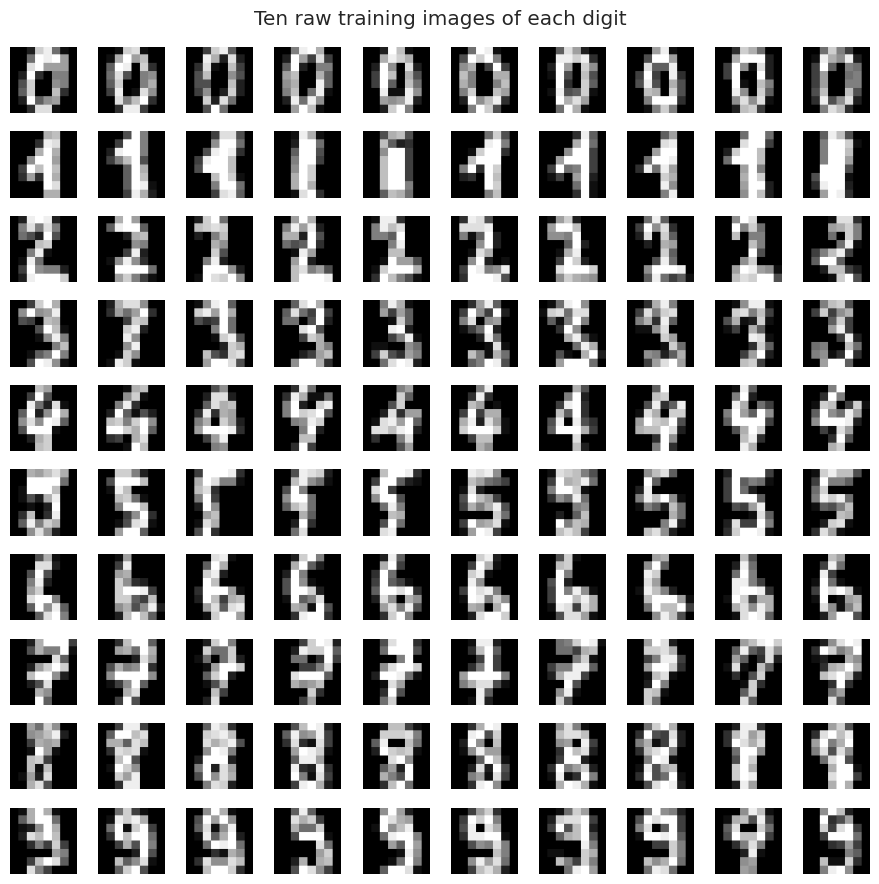

In [3]:
fig, axes = plt.subplots(10, 10, figsize=(9, 9))
for d in range(10):
    files = sorted((prep.RAW_DIR / "train" / str(d)).iterdir())[:10]
    for k, f in enumerate(files):
        axes[d, k].imshow(Image.open(f), cmap="gray"); axes[d, k].axis("off")
plt.suptitle("Ten raw training images of each digit"); plt.tight_layout(); plt.show()

## 2. Exploring the data

Images have no columns, so we measure features from each one (after preprocessing, see section 3):

| Feature | How it is computed | Why it matters |
|---|---|---|
| Class count | images per folder | imbalance would bias the model |
| Aspect ratio | width ÷ height of the digit's bounding box | some digits are naturally narrow |
| Ink coverage | share of pixels that are part of the stroke | how much "material" each digit has |
| Top-heaviness | share of ink in the top half | where the mass of the digit sits |
| Average image | mean of all images of a digit | how consistently people write it |

In [4]:
prep.process_dataset()        # explained in section 3; done here so features use the final format
feats = prep.dataset_features(config.TRAIN_DIR)
feats.groupby("label")[["aspect_ratio", "ink_coverage", "top_heaviness", "stroke_intensity"]].agg(["mean", "std"]).round(3)

aspect_ratio        ink_coverage        top_heaviness         \
              mean    std         mean    std          mean    std   
label                                                                
0            0.879  0.151        0.528  0.080         0.500  0.035   
1            0.521  0.185        0.301  0.096         0.497  0.055   
2            0.886  0.171        0.462  0.081         0.420  0.065   
3            0.789  0.150        0.447  0.088         0.520  0.054   
4            0.806  0.137        0.413  0.075         0.520  0.096   
5            0.874  0.208        0.430  0.088         0.549  0.062   
6            0.762  0.131        0.445  0.085         0.332  0.053   
7            0.788  0.142        0.395  0.077         0.637  0.065   
8            0.760  0.146        0.488  0.082         0.530  0.044   
9            0.736  0.129        0.427  0.080         0.645  0.066   

      stroke_intensity         
                  mean    std  
label                          
0                0.555  0.064  
1                0.562  0.091  
2                0.568  0.070  
3                0.555  0.064  
4                0.543  0.072  
5                0.533  0.072  
6                0.558  0.071  
7                0.553  0.065  
8                0.561  0.070  
9                0.538  0.066

### Feature 1: class distribution

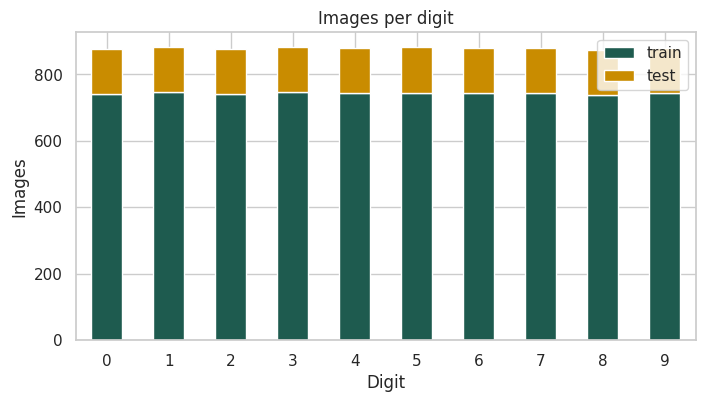

Largest / smallest class: 1.01


In [5]:
train_counts, test_counts = prep.class_counts(config.TRAIN_DIR), prep.class_counts(config.TEST_DIR)
ax = pd.DataFrame({"train": train_counts, "test": test_counts}).plot.bar(stacked=True, figsize=(8, 4), color=["#1E5B4F", "#C98C00"])
ax.set(xlabel="Digit", ylabel="Images", title="Images per digit"); plt.xticks(rotation=0); plt.show()
print(f"Largest / smallest class: {max(train_counts.values()) / min(train_counts.values()):.2f}")

**Interpretation.** Every digit has roughly 740–750 training images; the largest class is only 1.01 times the
smallest. The dataset is balanced, so the model has no incentive to favour any digit, and plain accuracy is a fair
headline metric. We still report macro-averaged precision, recall and F1 so a weak digit cannot hide behind a good
average.

### Feature 2: digit width (aspect ratio)

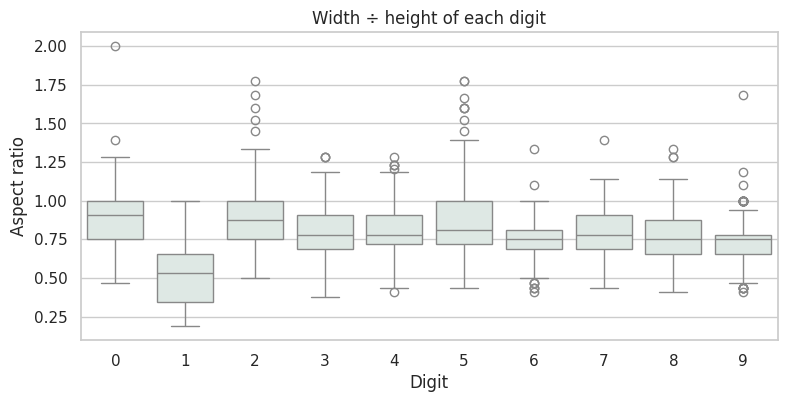

In [6]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=feats, x="label", y="aspect_ratio", color="#DCEAE5")
plt.title("Width ÷ height of each digit"); plt.xlabel("Digit"); plt.ylabel("Aspect ratio"); plt.show()

**Interpretation.** Digit 1 is by far the narrowest (mean width ÷ height 0.52) and also the most variable
(std 0.19), because writers draw it anywhere from a thin vertical stroke to a slanted line with a flag. The widest
digits are 2 (0.89), 0 (0.88) and 5 (0.87). The rest sit between 0.74 and 0.81 (9 is the narrowest of these at
0.74, then 8 and 6 at 0.76) and their boxes overlap heavily. So width separates 1 from everything else, but it
cannot tell most other digits apart: the model has to learn their shapes, which is why a CNN suits this data.

### Feature 3: ink coverage and top-heaviness

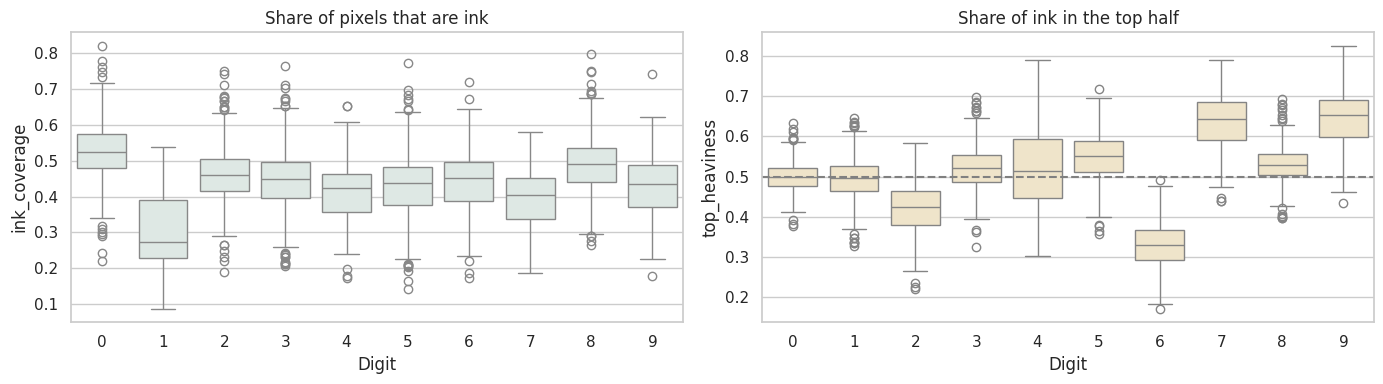

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=feats, x="label", y="ink_coverage", color="#DCEAE5", ax=ax[0])
ax[0].set(title="Share of pixels that are ink", xlabel="Digit")
sns.boxplot(data=feats, x="label", y="top_heaviness", color="#F5E6C4", ax=ax[1])
ax[1].axhline(0.5, color="grey", ls="--"); ax[1].set(title="Share of ink in the top half", xlabel="Digit")
plt.tight_layout(); plt.show()

**Interpretation.** Ink coverage is similar for most digits (about 40–49% of the image). The exceptions are 1,
which uses far less ink (30%), and 0, which uses the most (53%). Apart from those two, the amount of ink says
little about which digit it is. Top-heaviness is more useful:

- Top-heavy: 9 (0.65) and 7 (0.64) carry most of their ink above the middle line; 5 leans the same way (0.55).
- Bottom-heavy: 6 is strongly bottom-heavy (0.33) because its loop sits low, and 2 (0.42) because of its flat base.
- Balanced: 0 and 1 are almost exactly even (0.50), with 3, 4 and 8 just above (0.52–0.53). 4 varies the most
  between writers (std 0.10), since some close the top and others leave it open.

Digits on opposite sides of the line, like 6 and 9, are easy to tell apart. Digits on the same side, like 3 and 8,
need finer shape detail, and that's where the model is most likely to make mistakes.


### Feature 4: the average digit

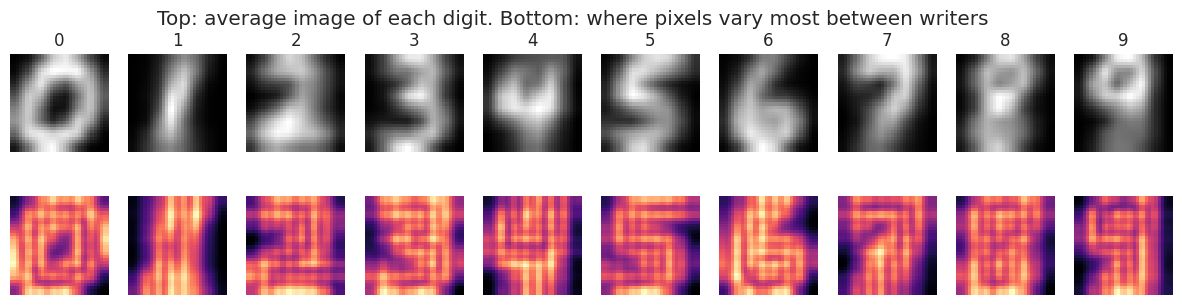

In [8]:
means = prep.mean_images(config.TRAIN_DIR, size=32)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for d in range(10):
    m = np.array(means[str(d)])
    axes[0, d].imshow(m, cmap="gray"); axes[0, d].set_title(str(d)); axes[0, d].axis("off")
    stack = np.stack([np.asarray(Image.open(f), dtype=np.float32) / 255 for f in (config.TRAIN_DIR / str(d)).iterdir()])
    axes[1, d].imshow(stack.std(0), cmap="magma"); axes[1, d].axis("off")
axes[0, 0].set_ylabel("mean"); axes[1, 0].set_ylabel("std")
plt.suptitle("Top: average image of each digit. Bottom: where pixels vary most between writers"); plt.show()

**Interpretation.** The top row shows that most digits have a clear, recognisable average shape: 0, 2, 3, 5, 6, 8 and 9 look sharp, so people write them in a fairly consistent way. 1, 4 and 7 are the blurriest, which means they have the most writing styles:

1: some writers draw a straight line, others slant it or add a flag.
4: some close the top, others leave it open.
7: some add a crossbar, others don't.

The bottom row shows where writers disagree most. For 1, the bright band spreads across the whole width because the stroke's position and slant vary. For the other digits, variation follows the stroke edges and loops. These bright regions are the pixels the CNN has to rely on to separate similar-looking digits.

## 3. Preprocessing

Steps, in order:

1. **Canonicalize** every image with `prep.canonicalize()`:
   grayscale → invert if the background is light (so photos of ink on paper match the dataset's white-on-black)
   → stretch contrast → crop to the digit → pad to a square → shrink to **8×8** (the dataset's native resolution)
   → enlarge to **32×32**. The same function runs on uploads and on the image sent to `/predict`, so the model
   always sees the same format.
2. **Load** with `image_dataset_from_directory` as single-channel 32×32 images.
3. **Split** the training folder 80/20 into train and validation (fixed seed).
4. **Batch** (32), **cache**, **shuffle** the training set and **prefetch**.
5. **Augment** (training only): rotation ±5%, shift ±10%, zoom ±10%. No flips, because a mirrored 2 is not a 2.
6. **Scale** pixels from 0–255 to 0–1 (a `Rescaling` layer inside the model).

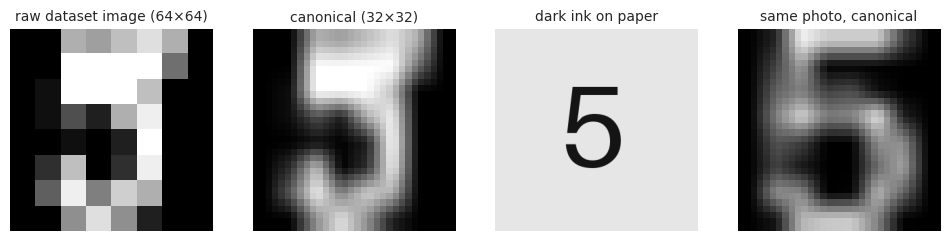

In [9]:
raw = sorted((prep.RAW_DIR / "train" / "5").iterdir())[0]
paper = Image.new("L", (300, 300), 230)
from PIL import ImageDraw, ImageFont
ImageDraw.Draw(paper).text((95, 40), "5", fill=20, font=ImageFont.load_default(size=170))

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, img, t in zip(ax, [Image.open(raw), prep.canonicalize(raw), paper, prep.canonicalize(paper)],
                     ["raw dataset image (64×64)", "canonical (32×32)", "dark ink on paper", "same photo, canonical"]):
    a.imshow(img, cmap="gray", vmin=0, vmax=255); a.set_title(t, fontsize=10); a.axis("off")
plt.show()

In [10]:
train_ds, val_ds, class_names = prep.load_datasets()
test_ds = prep.load_test_dataset(class_names=class_names)
x, y = next(iter(train_ds))
print("classes:", class_names)
print("batch:", x.shape, x.dtype, "| pixel range:", float(tf.reduce_min(x)), "to", float(tf.reduce_max(x)))

Found 7437 files belonging to 10 classes.
Using 5950 files for training.
Found 7437 files belonging to 10 classes.
Using 1487 files for validation.
Found 1360 files belonging to 10 classes.


classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
batch: (32, 32, 32, 1) <dtype: 'float32'> | pixel range: 0.0 to 255.0


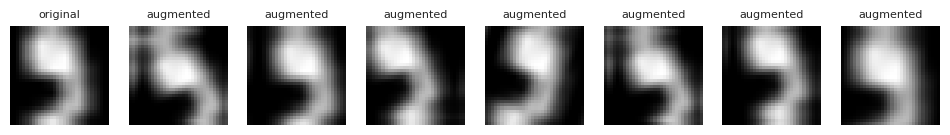

In [11]:
aug = prep.augmentation_layer()
plt.figure(figsize=(12, 2.4))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    img = x[:1] if i == 0 else aug(x[:1], training=True)
    plt.imshow(img[0, :, :, 0], cmap="gray"); plt.axis("off"); plt.title("original" if i == 0 else "augmented", fontsize=8)
plt.show()

## 4. Model creation

A small convolutional network:

```
input 32×32×1 → augmentation → rescale to 0–1
→ [conv 32 → batch-norm → conv 32 → max-pool → dropout 0.25]
→ [conv 64 → batch-norm → conv 64 → max-pool → dropout 0.25]
→ flatten → dense 128 (ReLU, L2) → dropout 0.4 → softmax over 10 digits
```

- **Convolutions** learn local stroke patterns (curves, corners, endings) wherever they appear.
- **Batch normalisation** stabilises and speeds up training.
- **Dropout, L2 and augmentation**: three kinds of regularisation, needed with only ~1,150 training images.
- **Adam** (learning rate 0.001), **early stopping** on validation loss with best weights restored, and
  **ReduceLROnPlateau** to halve the learning rate when progress stalls.

In [12]:
model = mdl.build_model(len(class_names))
model.summary()

Model: "digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_0_1 (Rescaling)           │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,082 (2.25 MB)

 Trainable params: 590,890 (2.25 MB)

 Non-trainable params: 192 (768.00 B)

## 5. Training

In [13]:
history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=mdl.get_callbacks(), verbose=2)
history = mdl.history_dict(history)

Epoch 1/40


/workspaces/Digit-Classifier-MLOps-Pipeline/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2026-11-26 17:24:39.718122: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23592960 exceeds 10% of free system memory.
2026-11-26 17:24:39.756657: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 21528576 exceeds 10% of free system memory.
2026-11-26 17:24:39.763360: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 21528576 exceeds 10% of free system memory.
2026-11-26 17:24:39.786657: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 28311552 exceeds 10% of free system memory.
2026-11-26 17:24:39.874896: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23592960 exceeds 10% of free system memory.


186/186 - 26s - 141ms/step - accuracy: 0.3850 - loss: 1.8218 - val_accuracy: 0.2213 - val_loss: 2.2156 - learning_rate: 0.0010
Epoch 2/40
186/186 - 21s - 113ms/step - accuracy: 0.5913 - loss: 1.2053 - val_accuracy: 0.3833 - val_loss: 1.8849 - learning_rate: 0.0010
Epoch 3/40
186/186 - 21s - 110ms/step - accuracy: 0.6692 - loss: 0.9861 - val_accuracy: 0.8171 - val_loss: 0.7012 - learning_rate: 0.0010
Epoch 4/40
186/186 - 41s - 220ms/step - accuracy: 0.7005 - loss: 0.8995 - val_accuracy: 0.9280 - val_loss: 0.3166 - learning_rate: 0.0010
Epoch 5/40
186/186 - 21s - 113ms/step - accuracy: 0.7249 - loss: 0.8374 - val_accuracy: 0.9428 - val_loss: 0.2486 - learning_rate: 0.0010
Epoch 6/40
186/186 - 21s - 112ms/step - accuracy: 0.7587 - loss: 0.7494 - val_accuracy: 0.9267 - val_loss: 0.2882 - learning_rate: 0.0010
Epoch 7/40
186/186 - 20s - 108ms/step - accuracy: 0.7716 - loss: 0.7008 - val_accuracy: 0.9341 - val_loss: 0.2580 - learning_rate: 0.0010
Epoch 8/40
186/186 - 21s - 111ms/step - accur

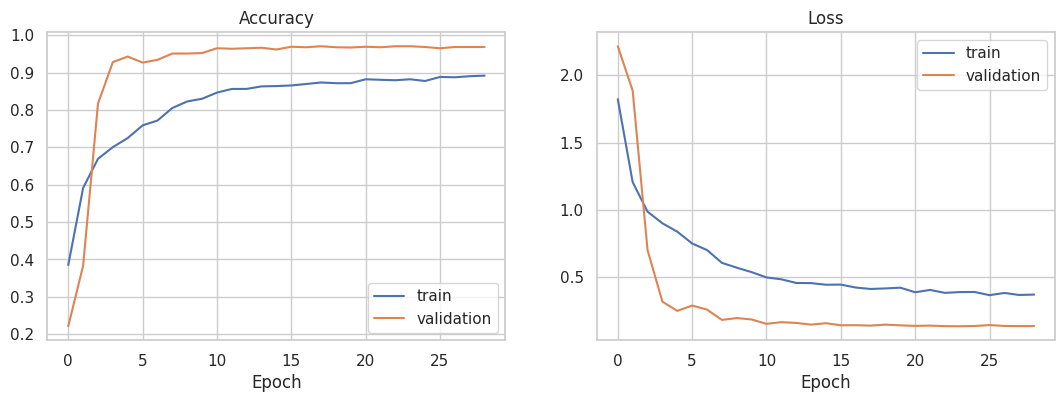

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, a in (("accuracy", ax[0]), ("loss", ax[1])):
    a.plot(history[k], label="train"); a.plot(history["val_" + k], label="validation")
    a.set(title=k.title(), xlabel="Epoch"); a.legend()
plt.show()

**Reading the curves.** Training accuracy rises and training loss falls steadily across all 29 epochs. Validation
is unstable at the start, while batch normalisation is still settling: validation accuracy is only 0.22 after
epoch 1, then jumps to 0.82 at epoch 3 and 0.93 at epoch 4. From there it climbs slowly, passing 0.96 at epoch 11
and levelling off around 0.97, while validation loss falls from 2.2 to about 0.13. The learning rate was halved
seven times by `ReduceLROnPlateau` as progress slowed.

Validation accuracy stays above training accuracy throughout (about 0.97 against 0.89 at the end). That is
expected: dropout and augmentation make training harder on purpose and are switched off during validation. The
lowest validation loss (0.134) came at epoch 24; early stopping ended training at epoch 29, after five epochs
without improvement, and restored the epoch-24 weights. There is no sign of overfitting.

## 6. Model testing

On the 360 held-out test images:

- **Accuracy**: share classified correctly.
- **Precision** per digit: when the model says "3", how often it is a 3.
- **Recall** per digit: of all real 3s, how many it finds.
- **F1**: harmonic mean of precision and recall, macro (each digit equal) and weighted.
- **Log loss**: punishes confident mistakes, so it measures how trustworthy the probabilities are.
- **ROC-AUC (one-vs-rest)**: how well each digit is ranked above the others.
- **Confusion matrix**: which digits get mixed up.

In [15]:
metrics = mdl.evaluate_model(model, test_ds, class_names)
pd.Series({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, name="test set").to_frame()

2026-11-26 17:35:39.079373: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,test set
accuracy,0.9772
precision_macro,0.9773
recall_macro,0.9772
f1_macro,0.9771
precision_weighted,0.9773
recall_weighted,0.9772
f1_weighted,0.9772
log_loss,0.0816
roc_auc_ovr,0.9993


In [16]:
pd.DataFrame(metrics["per_class"]).T.round(3)

,precision,recall,f1-score,support
0,0.985,0.993,0.989,136.000
1,0.978,0.985,0.982,136.000
2,0.971,0.985,0.978,135.000
3,0.971,0.978,0.975,137.000
4,0.971,0.993,0.982,136.000
5,0.978,0.985,0.982,137.000
6,0.992,0.971,0.981,136.000
7,0.971,0.978,0.974,136.000
8,0.984,0.933,0.958,135.000
9,0.971,0.971,0.971,136.000


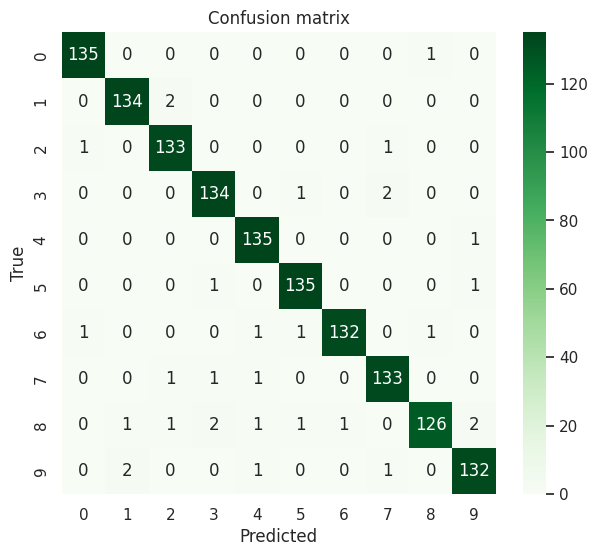

In [17]:
cm = np.array(metrics["confusion_matrix"])
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()

2026-11-26 17:35:43.065064: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


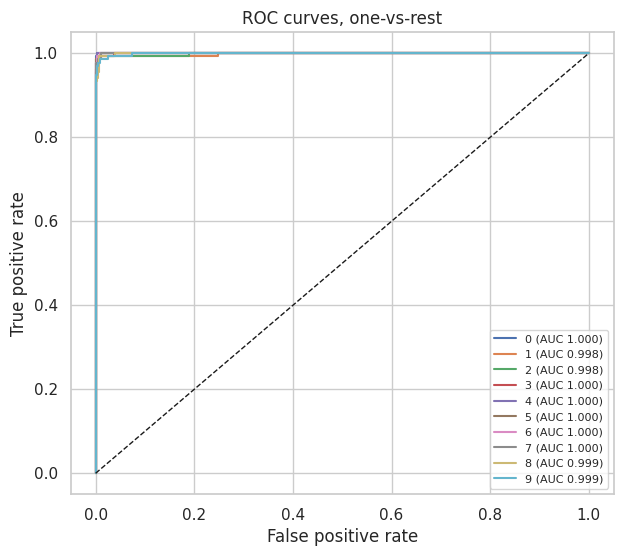

In [18]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
y_true, y_prob = mdl.predict_dataset(model, test_ds)
y_bin = label_binarize(y_true, classes=range(10))
plt.figure(figsize=(7, 6))
for i, c in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, one-vs-rest"); plt.legend(fontsize=8); plt.show()

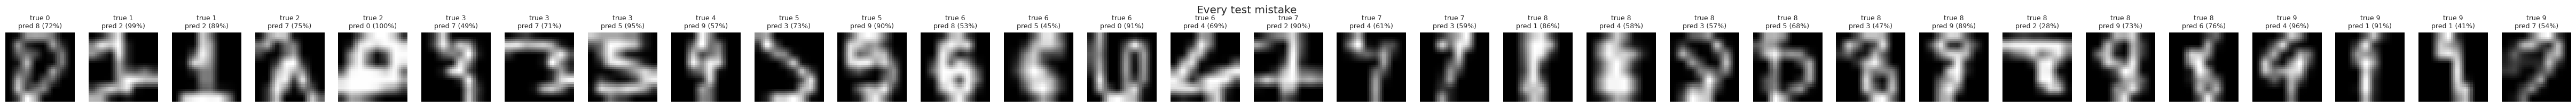

In [19]:
y_pred = y_prob.argmax(1)
test_files = [f for c in class_names for f in sorted((config.TEST_DIR / c).iterdir())]
wrong = np.where(y_pred != y_true)[0]
plt.figure(figsize=(2 * len(wrong), 2.4))
for k, i in enumerate(wrong):
    plt.subplot(1, len(wrong), k + 1); plt.imshow(Image.open(test_files[i]), cmap="gray"); plt.axis("off")
    plt.title(f"true {class_names[y_true[i]]}\npred {class_names[y_pred[i]]} ({y_prob[i].max():.0%})", fontsize=9)
plt.suptitle("Every test mistake"); plt.show()

**Conclusion.** The model classified 1,329 of 1,360 test images correctly: **97.7% accuracy**, with macro
precision, recall and F1 all at 0.977. Log loss is 0.082 and the macro one-vs-rest ROC-AUC is 0.999, so the
probabilities rank the right digit highly even when the top choice is wrong.

The 31 mistakes are spread thinly across many digits rather than concentrated in one confusion. Every digit has
recall of at least 97%, except **8**, the weakest digit: 126 of 135 found (recall 93.3%, F1 0.958). Its 9 errors
are spread over seven different digits; the most common are 3 and 9 (two each), which share its loops and
curves. This matches the feature analysis: 3, 8 and 9 all sit on the top-heavy side of the line and overlap in
width, so only fine shape detail separates them, and that detail is limited at 8×8.

The "every test mistake" figure shows that several errors are made with high confidence, so the model can be
confidently wrong on unusual handwriting. For the clinic use case that means the confidence score helps, but it
should not be the only check. Adding more varied 8s, 3s and 9s through retraining would be the most direct
improvement.

In [20]:
version = mdl.save_model(model, class_names, metrics, history, trigger="initial: notebook")
print("Saved", config.MODEL_PATH, "as version", version)

Saved /workspaces/Digit-Classifier-MLOps-Pipeline/models/digit_cnn.h5 as version 4


## 7. Prediction functions

`src/prediction.py` is what the API calls: it canonicalizes the image and returns the digit, the confidence and every class probability.

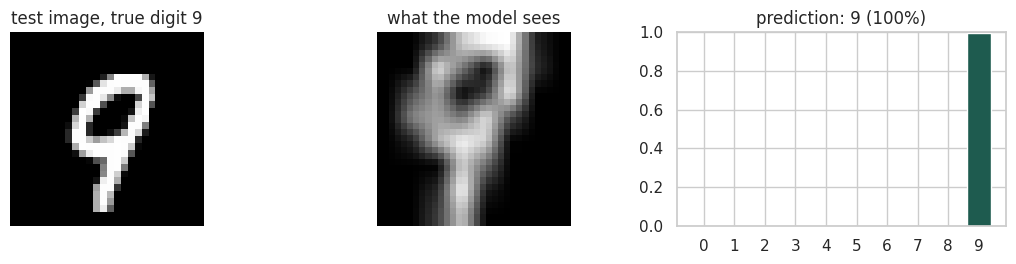

{'label': '9',
 'confidence': 0.9974064230918884,
 'probabilities': {'0': 1.7772153171335958e-07,
  '1': 3.234147527564346e-07,
  '2': 3.057313904264447e-07,
  '3': 7.047068265819689e-06,
  '4': 0.0014978083781898022,
  '5': 1.1919991266040597e-05,
  '6': 4.6957802229963264e-11,
  '7': 0.0006968455854803324,
  '8': 0.00037912355037406087,
  '9': 0.9974064230918884},
 'model_version': 4,
 'inference_ms': 19.18}

In [21]:
from src.prediction import Predictor
predictor = Predictor()

def show_prediction(image, title=""):
    r = predictor.predict(image)
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
    ax[0].imshow(Image.open(image) if isinstance(image, (str, Path)) else image, cmap="gray"); ax[0].set_title(title or "input"); ax[0].axis("off")
    ax[1].imshow(prep.canonicalize(image), cmap="gray"); ax[1].set_title("what the model sees"); ax[1].axis("off")
    ax[2].bar(list(r["probabilities"]), list(r["probabilities"].values()), color="#1E5B4F"); ax[2].set_ylim(0, 1)
    ax[2].set_title(f"prediction: {r['label']} ({r['confidence']:.0%})"); plt.tight_layout(); plt.show()
    return r

sample = random.choice(sorted((prep.RAW_DIR / "test").glob("*/*.png")))
show_prediction(sample, f"test image, true digit {sample.parent.name}")

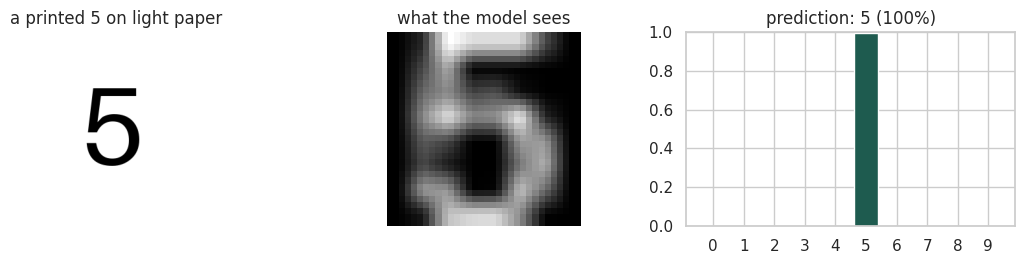

{'label': '5',
 'confidence': 0.9989618062973022,
 'probabilities': {'0': 2.1091582311782986e-06,
  '1': 2.1273975636670883e-10,
  '2': 3.092744504940015e-09,
  '3': 5.514152690011542e-06,
  '4': 3.869794795718917e-08,
  '5': 0.9989618062973022,
  '6': 0.0001689038035692647,
  '7': 1.2617024092165252e-09,
  '8': 0.0008451893809251487,
  '9': 1.646141754463315e-05},
 'model_version': 4,
 'inference_ms': 20.43}

In [22]:
buf = io.BytesIO(); paper.save(buf, "PNG")
show_prediction(Image.open(buf), "a printed 5 on light paper")

## 8. Retraining

How retraining works in production (`mdl.retrain`):

1. Users upload labelled digits (dashboard or `POST /upload`). Each image is canonicalized and saved to `data/uploads/<digit>/`.
2. **Trigger:** the *Retrain model* button, or automatically once `RETRAIN_THRESHOLD` (50) images are waiting.
3. Uploads move into `data/train` (20% into `data/test` so evaluation covers the new data).
4. The current model's weights are copied into a fresh network and training continues at a lower learning rate (warm start).
5. **Champion vs challenger:** old and new model are scored on the same test set; the new one goes live only if
   accuracy does not drop by more than 1%. The old file is archived in `models/archive/`.
6. Every API container notices the new model file and reloads it.

Here we simulate users uploading their own digits by drawing new ones with different fonts.
(In a real project these would be photos of handwritten digits.)

In [23]:
for d in range(10):
    for size in (120, 150, 180):
        img = Image.new("L", (260, 260), 235)
        ImageDraw.Draw(img).text((70, 20), str(d), fill=15, font=ImageFont.load_default(size=size))
        buf = io.BytesIO(); img.save(buf, "PNG")
        prep.save_uploads([(f"{d}_{size}.png", buf.getvalue())], label=str(d))
print("Pending uploads:", prep.pending_upload_count(), "| auto-trigger fires:", mdl.should_retrain())

Pending uploads: 33 | auto-trigger fires: False


In [24]:
result = mdl.retrain(trigger="manual: notebook demo", epochs=5)
result

Found 7470 files belonging to 10 classes.
Using 5976 files for training.
Found 7470 files belonging to 10 classes.
Using 1494 files for validation.
Found 1360 files belonging to 10 classes.


Epoch 1/5


/workspaces/Digit-Classifier-MLOps-Pipeline/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/187 - 23s - 125ms/step - accuracy: 0.8770 - loss: 0.3971 - val_accuracy: 0.9612 - val_loss: 0.1270 - learning_rate: 3.0000e-04
Epoch 2/5
187/187 - 20s - 107ms/step - accuracy: 0.8864 - loss: 0.3783 - val_accuracy: 0.9639 - val_loss: 0.1195 - learning_rate: 3.0000e-04
Epoch 3/5


187/187 - 21s - 113ms/step - accuracy: 0.8842 - loss: 0.3835 - val_accuracy: 0.9679 - val_loss: 0.1186 - learning_rate: 3.0000e-04
Epoch 4/5
187/187 - 41s - 218ms/step - accuracy: 0.8887 - loss: 0.3603 - val_accuracy: 0.9679 - val_loss: 0.1299 - learning_rate: 3.0000e-04
Epoch 5/5
187/187 - 40s - 216ms/step - accuracy: 0.8870 - loss: 0.3666 - val_accuracy: 0.9625 - val_loss: 0.1306 - learning_rate: 3.0000e-04


2026-11-26 17:38:20.177204: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


{'trigger': 'manual: notebook demo',
 'new_images': {'6': 3,
  '4': 4,
  '9': 3,
  '5': 3,
  '2': 4,
  '0': 3,
  '1': 4,
  '8': 3,
  '7': 3,
  '3': 3},
 'promoted': True,
 'old_accuracy': 0.9772058823529411,
 'new_accuracy': 0.9742647058823529,
 'new_f1_macro': np.float64(0.9742308214187607),
 'duration_s': 154.0,
 'version': 5}

In [25]:
pd.DataFrame(mdl.read_json(config.META_PATH)["versions"])

,version,trained_at,trigger,accuracy,f1_macro,n_train,new_images
0,1,2026-11-25T12:42:41+00:00,initial: notebook,0.994444,0.994356,1437,NaN
1,2,2026-11-25T12:43:16+00:00,manual: notebook demo,0.988889,0.988726,1467,30.0
2,3,2026-11-26T11:08:53+00:00,initial,0.977941,0.977935,7437,NaN
3,4,2026-11-26T17:35:45+00:00,initial: notebook,0.977206,0.977135,7437,NaN
4,5,2026-11-26T17:38:20+00:00,manual: notebook demo,0.974265,0.974231,7470,33.0


## Summary

*Data:* 8,797 handwritten digits: the 1,797 UCI/scikit-learn digits (8×8) plus a 7,000-image MNIST sample, added so the model sees many more writing styles. Balanced at about 745 training and 136 test images per digit: 7,437 for training and 1,360 held out for testing.

*Features:* Ink coverage overlaps heavily between digits (only 1 clearly uses less ink, 0 the most), and width mainly separates 1. Top-heaviness is more telling: 7 and 9 carry their ink high, 6 and 2 low, and 4 varies the most between writers. So most digits can only be told apart by shape, which is why a CNN suits this data.

*Preprocessing:* One canonicalize() step crops, centres and reduces every image to 8×8 before enlarging it to 32×32, so both datasets, uploads and predictions all look the same. Augmentation (small rotations, shifts and zooms) reduces overfitting.

*Training:* The CNN trained for 29 epochs before early stopping restored the best weights (epoch 24), reaching about 97% validation accuracy. Validation stayed above training accuracy throughout because dropout and augmentation only apply during training, so there is no sign of overfitting.

*Testing:* 1,329 of 1,360 test images were correct (97.7% accuracy, macro F1 0.977), with a macro ROC-AUC of 0.999. Errors are spread thinly across many pairs; 8 is the weakest digit (126/135 correct); its errors are spread over seven digits, most often 3 and 9 (two each).

*Prediction:* A test-set 9 and a printed 5 on light paper were read with 99.7% and 99.9% confidence, showing that preprocessing lets the model handle images that look quite different from the original dataset.

*Retraining:* The demo merged 33 new images and fine-tuned the model. The retrained model (version 5) scored 97.4%, 0.3 points below version 4, and was still promoted because the drop is within the 1-point tolerance. Version 5 is the model saved in `models/digit_cnn.h5`. With real handwritten uploads, or a tolerance of 0, a weaker model would not go live.